# Models, training and evaluation · Yash
**Project 24 · Activity Recognition System · Review 2.** Run the cells top to bottom (Jupyter: kernel *har*; Colab: run the setup cell first, it fetches the data and models).

In [1]:
import os, sys, subprocess, pathlib, urllib.request, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not os.path.exists("/content/activity-recognition"):
        subprocess.run(["git", "clone", "-q", "https://github.com/rajyyug1132/activity-recognition", "/content/activity-recognition"], check=True)
    os.chdir("/content/activity-recognition")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mediapipe", "scikit-learn==1.9.1"], check=True)
    os.makedirs("data/uci", exist_ok=True); os.makedirs("models", exist_ok=True)
    if not os.path.exists("data/uci/UCI HAR Dataset"):
        urllib.request.urlretrieve("https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip", "data/uci/har.zip")
        zipfile.ZipFile("data/uci/har.zip").extractall("data/uci")
        zipfile.ZipFile("data/uci/UCI HAR Dataset.zip").extractall("data/uci")
    if not os.path.exists("models/pose_landmarker_full.task"):
        urllib.request.urlretrieve("https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/latest/pose_landmarker_full.task", "models/pose_landmarker_full.task")
    from google.colab import drive
    drive.mount("/content/drive")
    for f in ["cnn_uci.keras", "video_rf.joblib"]:
        if os.path.exists(f"/content/drive/MyDrive/{f}"):
            subprocess.run(["cp", f"/content/drive/MyDrive/{f}", f"models/{f}"], check=True)
elif pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")                      # run from the repository root

sys.path.insert(0, "src")
for f in ["config/config.yaml", "app/demo/uci_test_person_12.csv", "data/uci/UCI HAR Dataset",
          "models/cnn_uci.keras", "models/video_rf.joblib", "models/pose_landmarker_full.task"]:
    print("found  " if os.path.exists(f) else "MISSING", f)

found   config/config.yaml
found   app/demo/uci_test_person_12.csv
found   data/uci/UCI HAR Dataset
found   models/cnn_uci.keras
found   models/video_rf.joblib
found   models/pose_landmarker_full.task


In [2]:
%matplotlib inline
import inspect, yaml, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Code, Image, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(fn):
    """Print a function's source exactly as it is in src/."""
    display(Code(inspect.getsource(fn), language="python"))

cfg = yaml.safe_load(open("config/config.yaml"))
DEMO = "app/demo/uci_test_person_12.csv"
NAMES = {"WALKING": "Walking", "WALKING_UPSTAIRS": "Upstairs", "WALKING_DOWNSTAIRS": "Downstairs",
         "SITTING": "Sitting", "STANDING": "Standing", "LAYING": "Lying"}
COLOURS = {"WALKING": "#2bb3a3", "WALKING_DOWNSTAIRS": "#2b3a8f", "WALKING_UPSTAIRS": "#7fb8e6",
           "SITTING": "#e9853a", "STANDING": "#e8c547", "LAYING": "#7a2e6e"}

## 4. Models, training and evaluation · Yash
**What to say**
- Three models: a Random Forest on UCI's 561 ready-made features (92.9%), a 1D-CNN on raw windows (91.0%, the model in the app), and an LSTM for comparison (88.1%).
- `build_cnn`: two 1D convolution layers, dropout, a dense layer, and a softmax over the six activities.
- `fit` trains with early stopping on three held-out training people and keeps the best epoch, so the model stops before it overfits.
- Below, the saved CNN is scored once on the 9 test people it never saw.

In [3]:
from models import build_cnn
from train import fit
show(build_cnn)
show(fit)

def build_cnn(input_shape=(128, 9), n_classes=6):
    from tensorflow import keras
    from tensorflow.keras import layers
    m = keras.Sequential([
        keras.Input(shape=input_shape),
        layers.Conv1D(64, 5, activation="relu"),
        layers.Conv1D(64, 5, activation="relu"),
        layers.Dropout(0.5),
        layers.MaxPooling1D(2),
        layers.Flatten(),
        layers.Dense(100, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def fit(model, X_tr, y_tr, X_val, y_val, cfg):
    """Returns (model, history). history is None for sklearn models."""
    if not hasattr(model, "compile"):                     # sklearn: no epochs
        return model.fit(X_tr, y_tr), None
    from tensorflow import keras
    keras.utils.set_random_seed(cfg["seed"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=30,
                  batch_size=64, callbacks=[stop], verbose=2)
    return model, h.history

In [4]:
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
model = tf.keras.models.load_model("models/cnn_uci.keras")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 124, 64)        │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 120, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3840)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       384,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           606 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,224,584 (4.67 MB)

 Trainable params: 408,194 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 816,390 (3.11 MB)

9 people never seen: accuracy 91.0%, macro F1 0.909
per person: 2:92% 4:81% 9:82% 10:69% 12:95% 13:100% 18:97% 20:97% 24:100%


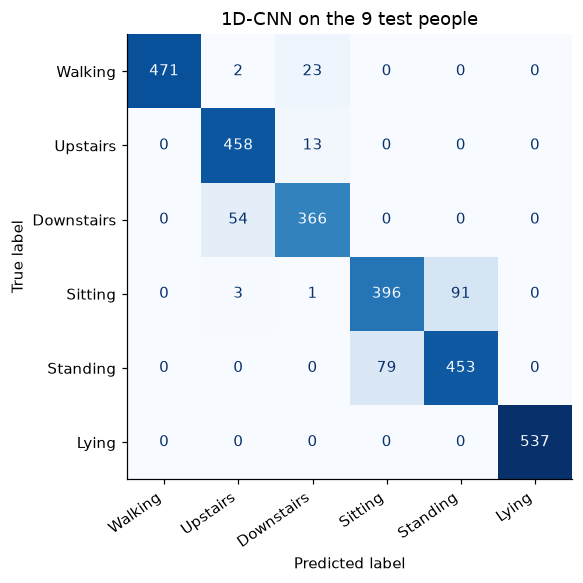

In [5]:
from data_loader import _raw
from preprocess import normalize
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from inference import ACTS
R = "data/uci/UCI HAR Dataset"
te = {"X_raw": _raw(R, "test"), "y": np.loadtxt(f"{R}/test/y_test.txt", dtype=int) - 1,
      "subject": np.loadtxt(f"{R}/test/subject_test.txt", dtype=int)}
pred = model.predict(normalize(te["X_raw"], cfg["norm_stats"]), verbose=0).argmax(1)
print(f"9 people never seen: accuracy {accuracy_score(te['y'], pred):.1%}, macro F1 {f1_score(te['y'], pred, average='macro'):.3f}")
per_person = pd.Series({s: accuracy_score(te["y"][te["subject"] == s], pred[te["subject"] == s]) for s in sorted(set(te["subject"]))})
print("per person:", " ".join(f"{s}:{a:.0%}" for s, a in per_person.items()))
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ConfusionMatrixDisplay.from_predictions(te["y"], pred, display_labels=[NAMES[a] for a in ACTS], ax=ax, colorbar=False, cmap="Blues")
ax.set_title("1D-CNN on the 9 test people"); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

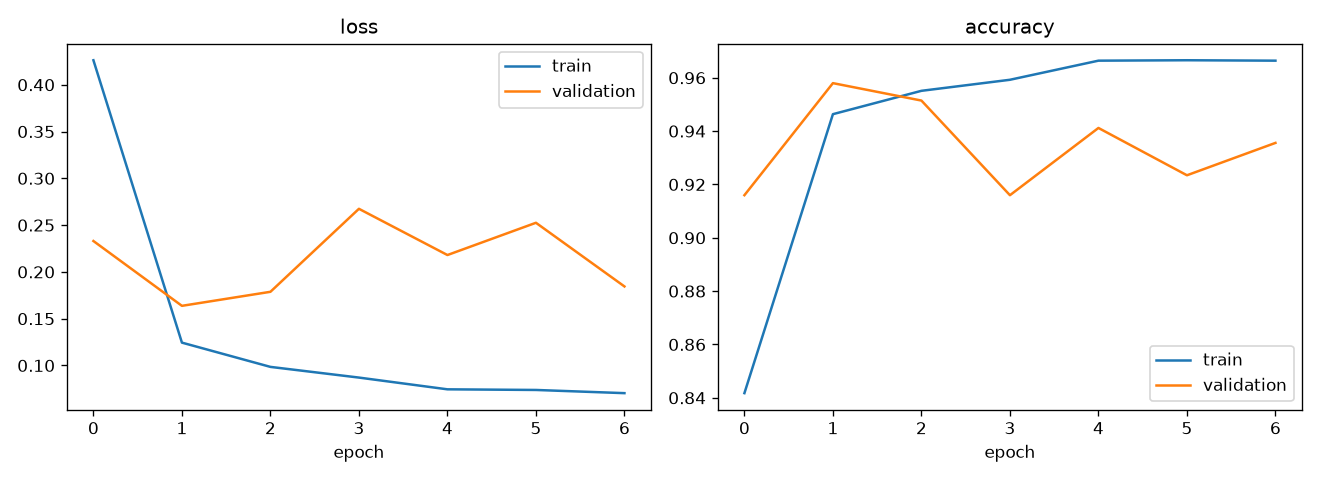

In [6]:
display(Image("reports/figures/learning_curves.png", width=760))